## 1) Cài đặt & Import

In [9]:

# %pip install pandas numpy matplotlib scikit-learn scipy
# %pip install implicit
# %pip install surprise
# %pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
# %pip install xgboost
# %pip install tqdm

import os, math, random, itertools, json, time, datetime
from typing import List, Dict, Any, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# For implicit ALS
try:
    import implicit
except Exception as e:
    print("Note: 'implicit' not available yet. Use pip cell above if needed.", e)

# Surprise for SVD/kNN
try:
    from surprise import Dataset, Reader, SVD, KNNBaseline
    from surprise.model_selection import train_test_split as surprise_tts
    from surprise.model_selection import GridSearchCV as SurpriseGrid
    from surprise import accuracy as surprise_accuracy
except Exception as e:
    print("Note: 'surprise' not available. Use pip to install if you want SVD/kNN.", e)

# Deep Learning (PyTorch) for NCF/MLP/VAE
try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset as TorchDataset, DataLoader
except Exception as e:
    print("Note: 'torch' not available. Use pip to install if you want NCF/MLP/VAE.", e)

# XGBoost for gradient boosting
try:
    import xgboost as xgb
except Exception as e:
    print("Note: 'xgboost' not available. Use pip to install if you want XGB.", e)

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 160)


## 2) Sinh dữ liệu (hoặc nạp nếu đã có)

In [10]:

import csv, random, datetime
from typing import List, Dict, Any

# ----- Config -----
REGIONS = ['us-east', 'us-west', 'europe', 'asia', 'oceania', 'south-america', 'middle-east', 'africa']
REGION_WEIGHTS = [0.25, 0.20, 0.15, 0.15, 0.10, 0.05, 0.05, 0.05]
WORLD_CATEGORIES = ['Social', 'Gaming', 'Education', 'Art & Creative', 'Music & Dance',
                    'Sports & Fitness', 'Adventure', 'Relaxation', 'Horror', 'Puzzle',
                    'Roleplay', 'Comedy', 'Simulation', 'Strategy', 'Sci-Fi', 'Fantasy']
WORLD_CATEGORY_WEIGHTS = [0.15, 0.2, 0.1, 0.05, 0.1, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
TAGS = ['multiplayer', 'singleplayer', 'competitive', 'casual', 'story-driven',
        'sandbox', 'educational', 'meditation', 'fitness', 'music', 'art',
        'scary', 'funny', 'realistic', 'fantasy', 'sci-fi', 'retro',
        'minimalist', 'social', 'creative', 'immersive', ]
TAG_WEIGHTS = [0.15, 0.1, 0.1, 0.05, 0.1, 0.1, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05]
LANGUAGES = ['en', 'es', 'fr', 'de', 'ja', 'ko', 'zh', 'pt', 'ru', 'it', 'ar', 'hi']
LANGUAGE_WEIGHTS = [0.4, 0.2, 0.08, 0.07, 0.05, 0.05, 0.05, 0.05, 0.03, 0.02, 0.005, 0.005]
AGE_GROUPS = ['13-17', '18-24', '25-34', '35-44', '45-54', '55+']
AGE_WEIGHTS = [0.05, 0.35, 0.35, 0.15, 0.07, 0.03]
ACHIEVEMENT_TYPES = ['Explorer', 'Socializer', 'Creator', 'Competitor',
                     'Collector', 'Helper', 'Pioneer', 'Master', 'Veteran', 'Architect']
ACHIEVEMENT_TYPE_WEIGHTS = [0.2, 0.2, 0.2, 0.1, 0.1, 0.05, 0.05, 0.05, 0.025, 0.025]

class VRDataGenerator:
    def __init__(self):
        self.users: List[Dict[str, Any]] = []
        self.worlds: List[Dict[str, Any]] = []

    def generate_user_id(self) -> str:
        return f"U{random.randint(100000, 999999)}"

    def generate_connection_id(self) -> str:
        return f"C{random.randint(100000, 999999)}"

    def generate_world_id(self) -> str:
        return f"W{random.randint(1000000, 9999999)}"

    def generate_datetime(self, days_back: int = 365) -> str:
        now = datetime.datetime.now()
        delta = datetime.timedelta(days=random.randint(0, days_back),
                                   hours=random.randint(0, 23),
                                   minutes=random.randint(0, 59))
        return (now - delta).strftime('%Y-%m-%d %H:%M:%S')

    def generate_username(self) -> str:
        adjectives = ['Cool', 'Epic', 'Mystic', 'Shadow', 'Neon', 'Cyber', 'Dark', 'Wild', 'Hyper']
        nouns = ['Player', 'Gamer', 'Explorer', 'Creator', 'Wizard', 'Dragon', 'Ninja', 'Hero', 'Master']
        return f"{random.choice(adjectives)}{random.choice(nouns)}{random.randint(1, 9999)}"

    def generate_world_name(self) -> str:
        prefixes = ['The', 'Virtual', 'Meta', 'Neon', 'Quantum', 'Crystal', 'Dream', 'Galactic', 'Mystic']
        types = ['Arena', 'World', 'Realm', 'Hub', 'Oasis', 'Galaxy', 'Dungeon', 'Island', 'Kingdom']
        return f"{random.choice(prefixes)} {random.choice(types)}{random.randint(1, 9999)}"

    def generate_users(self, count: int = 300) -> List[Dict[str, Any]]:
        users = []
        for _ in range(count):
            users.append({
                'user_id': self.generate_user_id(),
                'user_name': self.generate_username(),
                'is_creator': random.choices(['true', 'false'],weights=[0.01,0.99], k=1)[0],
                'region': random.choices(REGIONS,weights =REGION_WEIGHTS, k=1)[0],
                'preferred_language': random.choices(LANGUAGES, weights =LANGUAGE_WEIGHTS, k=1 )[0],
                'age_group': random.choices(AGE_GROUPS, weights =AGE_WEIGHTS, k=1 )[0],
                'content_filter_level': random.choices(['none', 'low', 'medium', 'high'],weights =[0.4,0.2,0.2,0.2],k=1)[0],
                'preferred_categories': ','.join(random.sample(WORLD_CATEGORIES, k=random.randint(1, 3)))
            })
        self.users = users
        return users

    def generate_worlds(self, count: int = 80) -> List[Dict[str, Any]]:
        if not self.users:
            raise ValueError("Users must be generated first.")
        creator_pool = [u for u in self.users if u['is_creator'] == 'true'] or self.users
        worlds = []
        for _ in range(count):
            creator = random.choice(creator_pool)
            worlds.append({
                'world_id': self.generate_world_id(),
                'world_name': self.generate_world_name(),
                'creator_name': creator['user_name'],
                'category': random.choices(WORLD_CATEGORIES,weights= WORLD_CATEGORY_WEIGHTS,k=1)[0],
                'sub_category': random.choice(['Featured', 'Popular', 'New', 'Classic']),
                'tags': ','.join(random.choices([
                    'multiplayer','singleplayer','competitive','casual','story-driven','sandbox','educational','meditation',
                    'fitness','music','art','scary','funny','realistic','fantasy','sci-fi','retro','minimalist','social',
                    'creative','immersive'
                ], k=3)),
                'avg_session_minutes': round(random.uniform(1, 120), 1),
                'rating': round(random.uniform(1, 5), 1),
                'total_ratings': random.randint(0, 10000),
                'likes': random.randint(0, 50000),
                'max_players': random.choice([4, 8, 16, 32, 50, 100]),
                'current_players': random.randint(0, 50),
                'maturity_rating': random.choices(['E', 'E10+', 'T', 'M'],weights = [0.3,0.3,0.2,0.2], k=1)[0],
                'is_featured': random.choice(['true', 'false', 'false'])
            })
        self.worlds = worlds
        return worlds

    def generate_user_actions(self, count: int = 3000) -> List[Dict[str, Any]]:
        if not self.users or not self.worlds:
            raise ValueError("Users & Worlds must be generated first.")
        actions = []
        action_types = ['world_join', 'world_leave', 'world_like', 'world_rate',
                        'world_create', 'world_report', 'item_purchase',
                        'achievement_unlock']

        for _ in range(count):
            atype = random.choices(action_types, weights=[0.4,0.4,0.1,0.05,0.01,0.01,0.01,0.02], k=1)[0]
            if atype == 'world_rate':
                aval = str(random.randint(1,5))
            elif atype == 'world_like':
                aval = 'true'
            elif atype == 'world_join':
                aval = 'joined'
            elif atype == 'world_leave':
                aval = 'left'
            elif atype == 'world_create':
                aval = 'create'
            elif atype == 'world_report':
                aval = random.choice(['spam','abuse','other'])
            elif atype == 'item_purchase':
                aval = f"item{random.randint(1,1000)}"
            elif atype == 'achievement_unlock':
                aval = f"H{random.randint(100000,999999)}"
            else:
                aval = ''

            actions.append({
                'action_id': f"A{random.randint(100000,999999)}",
                'user_id': random.choice(self.users)['user_id'],
                'world_id': random.choice(self.worlds)['world_id'],
                'action_type': atype,
                'action_timestamp': self.generate_datetime(90),
                'action_value': aval
            })
        return actions

    def generate_achievements(self, count: int = 1000) -> List[Dict[str, Any]]:
        if not self.users:
            raise ValueError("Users must be generated first.")
        achievements = []
        names = ['First Steps', 'World Explorer', 'Social Butterfly', 'Champion',
                 'Collector', 'Master Creator', 'Veteran', 'Architect',
                 'Speed Runner', 'Puzzle Master', 'Survivor', 'Story Teller']
        for _ in range(count):
            achievements.append({
                'achievement_id': f"H{random.randint(100000, 999999)}",
                'user_id': random.choice(self.users)['user_id'],
                'achievement_name': random.choice(names),
                'achievement_type': random.choices(
                    ['Explorer','Socializer','Creator','Competitor','Collector','Helper','Pioneer','Master','Veteran','Architect'],
                    k=1
                )[0],
                'world_id': random.choice(self.worlds)['world_id'] if self.worlds else '',
                'earned_date': self.generate_datetime(365),
                'rarity': random.choices(['common', 'uncommon', 'rare', 'epic', 'legendary'], weights = [0.6,0.2,0.1,0.07,0.03],k=1)[0],
                'xp_reward': random.randint(10, 1000)
            })
        return achievements

    def generate_friend_connections(self, count: int = 1000) -> List[Dict[str, Any]]:
        if not self.users or len(self.users) < 2:
            raise ValueError("Users must be generated first and have at least 2 users.")
        connections = []
        for _ in range(count):
            user1 = random.choice(self.users)['user_id']
            user2 = random.choice(self.users)['user_id']
            while user2 == user1:
                user2 = random.choice(self.users)['user_id']

            connections.append({
                'connection_id': f"C{random.randint(100000, 999999)}",
                'user_id_1': user1,
                'user_id_2': user2,
                'connection_date': self.generate_datetime(365),
                'connection_strength': random.randint(1, 100),
                'mutual_friends_count': random.randint(0, 50),
                'interactions_count': random.randint(0, 1000),
                'last_interaction': self.generate_datetime(7),
                'favorite_world_together': random.choice(self.worlds)['world_id'] if self.worlds else '',
                'total_time_together_hours': round(random.uniform(0, 500), 1)
            })
        return connections

def save_to_csv(filename: str, data: List[Dict[str, Any]]):
    if not data:
        print(f"Empty data for {filename}")
        return
    import csv
    with open(filename, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=data[0].keys())
        writer.writeheader()
        writer.writerows(data)
    print(f"✓ Saved {len(data)} rows to {filename}")

DATA_DIR = 'data'
os.makedirs(DATA_DIR, exist_ok=True)

users_fp = os.path.join(DATA_DIR, 'users.csv')
worlds_fp = os.path.join(DATA_DIR, 'vrworld.csv')
actions_fp = os.path.join(DATA_DIR, 'user_actions.csv')
ach_fp = os.path.join(DATA_DIR, 'achievements.csv')
conn_fp = os.path.join(DATA_DIR, 'connections.csv')

if not (os.path.exists(users_fp) and os.path.exists(worlds_fp) and os.path.exists(actions_fp) and os.path.exists(ach_fp) and os.path.exists(conn_fp)):
    gen = VRDataGenerator()
    users = gen.generate_users(5000)
    save_to_csv(users_fp, users)
    worlds = gen.generate_worlds(400)
    save_to_csv(worlds_fp, worlds)
    actions = gen.generate_user_actions(40000)
    save_to_csv(actions_fp, actions)
    achievements = gen.generate_achievements(3000)
    save_to_csv(ach_fp, achievements)
    connections = gen.generate_friend_connections(10000)
    save_to_csv(conn_fp, connections)
else:
    print("Using existing CSVs in ./data")

# Load to DataFrames
users = pd.read_csv(users_fp)
worlds = pd.read_csv(worlds_fp)
actions = pd.read_csv(actions_fp)
achievements = pd.read_csv(ach_fp)
connections = pd.read_csv(conn_fp)

users.head(), worlds.head(), actions.head()


Using existing CSVs in ./data


(   user_id        user_name  is_creator   region preferred_language age_group content_filter_level                 preferred_categories
 0  U366447   NeonPlayer8547       False  us-west                 en     35-44                 high  Music & Dance,Art & Creative,Puzzle
 1  U953897  EpicCreator8434       False  us-west                 en     25-34                 high                   Simulation,Fantasy
 2  U290658  DarkCreator1401       False  us-east                 en     18-24               medium                               Horror
 3  U888340    WildGamer5777       False   africa                 en     25-34                 none          Adventure,Education,Fantasy
 4  U898431   NeonPlayer2534       False  us-west                 ko     25-34               medium           Strategy,Relaxation,Comedy,
    world_id         world_name      creator_name       category sub_category                           tags  avg_session_minutes  rating  total_ratings  \
 0  W4030713  Virtual

## 3) Khám phá & Tiền xử lý

Shapes: (5000, 8) (400, 14) (40000, 6) (3000, 8) (10000, 10)

Missing values:
                       users
user_id                   0
user_name                 0
is_creator                0
region                    0
preferred_language        0
age_group                 0
content_filter_level      0
preferred_categories      0
After filtering: (39472, 3)


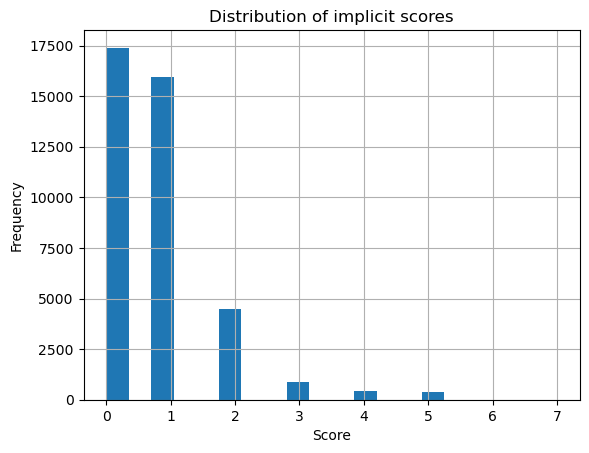

Users/Items: 4908 400
Train/Val: (31577, 5) (7895, 5)


,user_id,world_id,score,u_idx,i_idx
22885,U627032,W7662064,0.0,2824,298
37987,U963668,W3199074,0.0,4707,82
28154,U752155,W9640030,0.0,3486,378
10638,U345664,W9020302,0.0,1309,355
16409,U477659,W4617513,1.0,2014,134
24290,U662548,W7216970,1.0,3004,272
6189,U241732,W8477691,0.0,764,332
23641,U644687,W8668345,0.0,2919,341
15113,U448930,W2125870,1.0,1858,43
14123,U423724,W4030713,0.0,1740,111


,user_id,world_id,score,u_idx,i_idx
15284,U452583,W3217392,1.0,1877,83
39224,U992896,W7961509,1.0,4858,311
29253,U774948,W4996952,0.0,3621,152
20404,U571663,W3764202,0.0,2514,104
21323,U592843,W8477691,2.0,2623,332
27133,U726984,W8201160,1.0,3362,323
2105,U145353,W6910906,1.0,259,255
6267,U243248,W8037623,0.0,775,317
19558,U550977,W9071034,0.0,2406,357
21675,U601957,W4619951,1.0,2671,135


In [11]:

# Basic shapes and missing
print("Shapes:", users.shape, worlds.shape, actions.shape, achievements.shape, connections.shape)
print("\nMissing values:\n", pd.DataFrame({
    'users': users.isna().sum(),
}).dropna(how='all'))

# Interaction matrix base: we'll treat 'world_join' and 'world_like' and rating (if available)
# Construct implicit feedback score per (user, world)
# Score: join=1, like=2, rate=r (1..5), purchase=3
def interaction_score(row):
    t = row['action_type']
    v = row['action_value']
    if t == 'world_rate':
        try:
            return float(v)
        except:
            return 1.0
    elif t == 'world_like':
        return 2.0
    elif t == 'item_purchase':
        return 3.0
    elif t == 'world_join':
        return 1.0
    else:
        return 0.0

actions['score'] = actions.apply(interaction_score, axis=1)
inter_mat = actions.groupby(['user_id','world_id'])['score'].sum().reset_index()

# Filter a bit for density
user_counts = inter_mat['user_id'].value_counts()
world_counts = inter_mat['world_id'].value_counts()
active_users = set(user_counts[user_counts>=3].index)
popular_worlds = set(world_counts[world_counts>=3].index)
filtered = inter_mat[inter_mat['user_id'].isin(active_users) & inter_mat['world_id'].isin(popular_worlds)].copy()
print("After filtering:", filtered.shape)

# Visual distributions
fig = plt.figure()
filtered['score'].hist(bins=20)
plt.title("Distribution of implicit scores")
plt.xlabel("Score"); plt.ylabel("Frequency")
plt.show()

# Prepare id encoders
u_enc = LabelEncoder()
i_enc = LabelEncoder()
filtered['u_idx'] = u_enc.fit_transform(filtered['user_id'])
filtered['i_idx'] = i_enc.fit_transform(filtered['world_id'])

num_users = filtered['u_idx'].nunique()
num_items = filtered['i_idx'].nunique()
print("Users/Items:", num_users, num_items)

# Train/val split by interaction rows
train, val = train_test_split(filtered, test_size=0.2, random_state=42, stratify=filtered[['u_idx']])
print("Train/Val:", train.shape, val.shape)

# Quick look tables
display(train.head(10))
display(val.head(10))


## 4) Hàm đánh giá Top-K & trực quan

In [12]:

from collections import defaultdict

def precision_recall_at_k(preds_by_user: dict, truth_by_user: dict, k: int=10):
    precs, recs = [], []
    for u, truth in truth_by_user.items():
        recs_k = preds_by_user.get(u, [])[:k]
        if len(recs_k)==0:
            continue
        hit = len(set(recs_k) & set(truth))
        precs.append(hit/len(recs_k))
        recs.append(hit/max(1,len(truth)))
    return (np.mean(precs) if precs else 0.0), (np.mean(recs) if recs else 0.0)

def ndcg_at_k(preds_by_user: dict, truth_by_user: dict, k: int=10):
    ndcgs=[]
    for u, truth in truth_by_user.items():
        recs_k = preds_by_user.get(u, [])[:k]
        if not recs_k: 
            continue
        dcg=0.0
        for rank,item in enumerate(recs_k, start=1):
            if item in truth:
                dcg += 1.0/np.log2(rank+1)
        ideal_hits = min(len(truth), k)
        idcg = sum([1.0/np.log2(r+1) for r in range(1, ideal_hits+1)])
        ndcgs.append(dcg/(idcg if idcg>0 else 1))
    return np.mean(ndcgs) if ndcgs else 0.0

# Ground-truth: worlds in validation for each user
truth_by_user = defaultdict(list)
for _,r in val.iterrows():
    truth_by_user[r['u_idx']].append(r['i_idx'])
print("Example truth_by_user length:", len(truth_by_user))


Example truth_by_user length: 4879


## 5) ALS (implicit)

In [31]:
import scipy.sparse as sp
from implicit.als import AlternatingLeastSquares

# Tạo mapping từ toàn bộ users và worlds
user2id = {u: i for i, u in enumerate(users['user_id'].unique())}
item2id = {w: i for i, w in enumerate(worlds['world_id'].unique())}

# Dữ liệu tương tác từ train
rows = train['user_id'].map(user2id)
cols = train['world_id'].map(item2id)
data = [1] * len(train)

# Ma trận user–item đảm bảo đủ hàng cho mọi user
user_item_matrix = sp.coo_matrix(
    (data, (rows, cols)),
    shape=(len(user2id), len(item2id))
).tocsr()

# Huấn luyện ALS
als_model = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20)
als_model.fit(user_item_matrix)

# Sinh dự đoán top-10 cho mỗi user trong tập val
als_preds = {}
for uid in val['user_id'].unique():
    if uid in user2id:                      # chỉ predict cho user có trong train
        u_idx = user2id[uid]                # mapping sang index trong ALS
        recs, _ = als_model.recommend(u_idx, user_item_matrix[u_idx], N=10)
        als_preds[u_idx] = list(recs)       # ép recs thành list thay vì numpy array


# print(\"ALS training & prediction finished! als_preds sẵn sàng để evaluate.\")


  0%|          | 0/20 [00:00<?, ?it/s]

## 6) SVD & kNN (Surprise)

In [42]:
from surprise import Dataset, Reader, SVD, KNNBaseline, KNNBasic
from surprise import accuracy
from sklearn.preprocessing import MinMaxScaler
from surprise.model_selection import train_test_split as surprise_split

svd_preds, knn_preds = {}, {}
try:
    # Scale score về 0..10
    reader = Reader(rating_scale=(0, 10))
    temp = train.copy()
    temp['score_scaled'] = MinMaxScaler().fit_transform(temp[['score']]) * 10.0

    # ép user/item thành string
    temp['u_str'] = temp['u_idx'].astype(str)
    temp['i_str'] = temp['i_idx'].astype(str)

    # Surprise dataset
    data = Dataset.load_from_df(temp[['u_str','i_str','score_scaled']], reader)
    trainset, testset = surprise_split(data, test_size=0.2, random_state=42)

    # Train SVD
    svd = SVD(n_factors=64, reg_all=0.02, n_epochs=20, random_state=42)
    svd.fit(trainset)
    svd_test_preds = svd.test(testset)
    print("SVD RMSE:", accuracy.rmse(svd_test_preds, verbose=False))

    # Try KNN with MSD similarity (an toàn hơn cosine)
    try:
        sim_options = {'name': 'msd', 'user_based': False}
        knn = KNNBasic(sim_options=sim_options)
        knn.fit(trainset)
        knn_test_preds = knn.test(testset)
        print("KNNBasic (msd) RMSE:", accuracy.rmse(knn_test_preds, verbose=False))
    except Exception as e1:
        print("⚠️ KNNBasic failed:", e1)
        knn_preds = {}

    # Build candidate list per user (for Precision/Recall@10, NDCG)
    all_items = set(temp['i_str'].unique())
    user_train_items = temp.groupby('u_str')['i_str'].apply(set).to_dict()

    id2item = {str(i): i for i in temp['i_idx'].unique()}

    def topn_from_algo(algo, N=50):
        preds = {}
        for u in temp['u_str'].unique():
            seen = user_train_items.get(u, set())
            candidates = list(all_items - seen)
            ests = [(i, algo.predict(u, i).est) for i in candidates]
            ests.sort(key=lambda x: x[1], reverse=True)
            preds[int(u)] = [id2item[i] for i,_ in ests[:N]]  # convert về i_idx chuẩn
        return preds

    svd_preds = topn_from_algo(svd, 50)
    if 'knn' in locals():
        knn_preds = topn_from_algo(knn, 50)

    # Evaluate recommendation quality
    for name, pred in [('SVD', svd_preds), ('kNN', knn_preds)]:
        if pred:
            p, r = precision_recall_at_k(pred, truth_by_user, 10)
            nd = ndcg_at_k(pred, truth_by_user, 10)
            print(f"{name}@10 - Precision: {p:.4f}, Recall: {r:.4f}, NDCG: {nd:.4f}")
        else:
            print(f"{name} skipped.")

except Exception as e:
    print("Surprise SVD/kNN not available ->", e)


SVD RMSE: 1.3725709171380733
Computing the msd similarity matrix...
Done computing similarity matrix.
KNNBasic (msd) RMSE: 1.6591149818440771
SVD@10 - Precision: 0.0048, Recall: 0.0298, NDCG: 0.0142
kNN@10 - Precision: 0.0039, Recall: 0.0233, NDCG: 0.0120


## 7) NCF (NeuMF) & MLP (PyTorch)

In [16]:

ncf_preds, mlp_preds = {}, {}
try:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    class PairDataset(TorchDataset):
        def __init__(self, df: pd.DataFrame, num_items: int, num_neg: int=4):
            self.samples = []
            user_pos = df.groupby('u_idx')['i_idx'].apply(set).to_dict()
            rng = np.random.default_rng(123)
            for u, items in user_pos.items():
                for i in items:
                    self.samples.append((u, i, 1.0))
                    # negative sampling
                    for _ in range(num_neg):
                        j = rng.integers(0, num_items)
                        while j in items:
                            j = rng.integers(0, num_items)
                        self.samples.append((u, j, 0.0))
        def __len__(self): return len(self.samples)
        def __getitem__(self, idx):
            u,i,y = self.samples[idx]
            return torch.tensor(u), torch.tensor(i), torch.tensor(y, dtype=torch.float32)

    train_ds = PairDataset(train, num_items, num_neg=3)
    train_loader = DataLoader(train_ds, batch_size=1024, shuffle=True)

    class NeuMF(nn.Module):
        def __init__(self, n_users, n_items, k_gmf=16, k_mlp=64, layers=[128,64,32]):
            super().__init__()
            self.emb_u_g = nn.Embedding(n_users, k_gmf)
            self.emb_i_g = nn.Embedding(n_items, k_gmf)
            self.emb_u_m = nn.Embedding(n_users, k_mlp)
            self.emb_i_m = nn.Embedding(n_items, k_mlp)

            mlp_layers = []
            in_dim = 2*k_mlp
            for h in layers:
                mlp_layers += [nn.Linear(in_dim, h), nn.ReLU()]
                in_dim = h
            self.mlp = nn.Sequential(*mlp_layers)
            self.pred = nn.Linear(k_gmf + layers[-1], 1)
            self.sig = nn.Sigmoid()

        def forward(self, u, i):
            gmf = self.emb_u_g(u) * self.emb_i_g(i)
            mlp = torch.cat([self.emb_u_m(u), self.emb_i_m(i)], dim=1)
            mlp = self.mlp(mlp)
            x = torch.cat([gmf, mlp], dim=1)
            x = self.pred(x)
            return self.sig(x).squeeze(1)

    def train_model(model, loader, epochs=3, lr=1e-3):
        optim = torch.optim.Adam(model.parameters(), lr=lr)
        bce = nn.BCELoss()
        model.train()
        for ep in range(epochs):
            total=0
            for u,i,y in loader:
                u,i,y = u.to(device), i.to(device), y.to(device)
                p = model(u,i)
                loss = bce(p, y)
                optim.zero_grad(); loss.backward(); optim.step()
                total += loss.item()*u.size(0)
            print(f"Epoch {ep+1}: loss={total/len(loader.dataset):.4f}")

    # Train NeuMF
    neukf = NeuMF(num_users, num_items).to(device)
    train_model(neukf, train_loader, epochs=3, lr=1e-3)

    # Simple MLP (no GMF branch) for comparison
    class SimpleMLP(nn.Module):
        def __init__(self, n_users, n_items, k=64, layers=[128,64]):
            super().__init__()
            self.emb_u = nn.Embedding(n_users, k)
            self.emb_i = nn.Embedding(n_items, k)
            mlp_layers=[]; in_dim=2*k
            for h in layers:
                mlp_layers += [nn.Linear(in_dim, h), nn.ReLU()]
                in_dim = h
            self.mlp = nn.Sequential(*mlp_layers)
            self.out = nn.Linear(in_dim, 1); self.sig=nn.Sigmoid()
        def forward(self, u,i):
            x = torch.cat([self.emb_u(u), self.emb_i(i)], dim=1)
            x = self.mlp(x)
            return self.sig(self.out(x)).squeeze(1)

    mlp = SimpleMLP(num_users, num_items).to(device)
    train_model(mlp, train_loader, epochs=3, lr=1e-3)

    # Top-N prediction helper using model
    user_train_items = train.groupby('u_idx')['i_idx'].apply(set).to_dict()
    all_items = np.arange(num_items)

    @torch.no_grad()
    def topn_from_torch(model, N=50):
        model.eval()
        preds={}
        for u in range(num_users):
            seen = user_train_items.get(u, set())
            candidates = np.array(list(set(all_items) - seen))
            if len(candidates)==0:
                preds[u]=[]; continue
            u_batch = torch.tensor([u]*len(candidates), dtype=torch.long, device=device)
            i_batch = torch.tensor(candidates, dtype=torch.long, device=device)
            scores = model(u_batch, i_batch).cpu().numpy()
            order = np.argsort(-scores)[:N]
            preds[u] = candidates[order].tolist()
        return preds

    ncf_preds = topn_from_torch(neukf, 50)
    mlp_preds = topn_from_torch(mlp, 50)

    for name, pred in [('NCF', ncf_preds), ('MLP', mlp_preds)]:
        p, r = precision_recall_at_k(pred, truth_by_user, 10)
        nd = ndcg_at_k(pred, truth_by_user, 10)
        print(f"{name}@10 - Precision: {p:.4f}, Recall: {r:.4f}, NDCG: {nd:.4f}")

except Exception as e:
    print("PyTorch-based models not available ->", e)


Epoch 1: loss=0.5742
Epoch 2: loss=0.5624
Epoch 3: loss=0.5606
Epoch 1: loss=0.5682
Epoch 2: loss=0.5621
Epoch 3: loss=0.5605
NCF@10 - Precision: 0.0040, Recall: 0.0247, NDCG: 0.0134
MLP@10 - Precision: 0.0042, Recall: 0.0253, NDCG: 0.0128


## 8) VAE cho Collaborative Filtering

In [17]:

vae_preds = {}
try:
    # Build dense user-item matrix (binary >0)
    from scipy.sparse import coo_matrix
    mat = coo_matrix((train['score'].values, (train['u_idx'].values, train['i_idx'].values)),
                     shape=(num_users, num_items)).tocsr()
    mat = (mat>0).astype(np.float32).toarray()

    class VAE(nn.Module):
        def __init__(self, n_items, h=256, z=64):
            super().__init__()
            self.enc = nn.Sequential(nn.Linear(n_items, h), nn.ReLU())
            self.mu = nn.Linear(h, z)
            self.logvar = nn.Linear(h, z)
            self.dec = nn.Sequential(nn.Linear(z, h), nn.ReLU(), nn.Linear(h, n_items), nn.Sigmoid())
        def forward(self, x):
            h = self.enc(x)
            mu, logvar = self.mu(h), self.logvar(h)
            std = torch.exp(0.5*logvar)
            eps = torch.randn_like(std)
            z = mu + eps*std
            recon = self.dec(z)
            return recon, mu, logvar

    def vae_loss(recon, x, mu, logvar):
        bce = nn.functional.binary_cross_entropy(recon, x, reduction='sum')
        kld = -0.5*torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        return (bce + kld)/x.size(0)

    vae = VAE(num_items).to(device)
    opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
    X = torch.tensor(mat, dtype=torch.float32).to(device)

    vae.train()
    for ep in range(5):
        opt.zero_grad()
        recon, mu, logvar = vae(X)
        loss = vae_loss(recon, X, mu, logvar)
        loss.backward(); opt.step()
        print(f"Epoch {ep+1}: loss={loss.item():.4f}")

    # Recommend by decoding each user's vector and masking seen items
    vae.eval()
    with torch.no_grad():
        recon, _, _ = vae(X)
        scores = recon.cpu().numpy()

    user_train_items = train.groupby('u_idx')['i_idx'].apply(set).to_dict()
    for u in range(num_users):
        seen = user_train_items.get(u, set())
        cand = np.array(list(set(range(num_items)) - seen))
        if cand.size==0:
            vae_preds[u]=[]; continue
        s = scores[u, cand]
        order = np.argsort(-s)[:50]
        vae_preds[u] = cand[order].tolist()

    p, r = precision_recall_at_k(vae_preds, truth_by_user, 10)
    nd = ndcg_at_k(vae_preds, truth_by_user, 10)
    print(f"VAE@10 - Precision: {p:.4f}, Recall: {r:.4f}, NDCG: {nd:.4f}")

except Exception as e:
    print("VAE not available ->", e)


Epoch 1: loss=280.8548
Epoch 2: loss=268.7546
Epoch 3: loss=257.1862
Epoch 4: loss=245.7400
Epoch 5: loss=234.6304
VAE@10 - Precision: 0.0039, Recall: 0.0240, NDCG: 0.0128


## 9) XGBoost (phân loại nhị phân) + Confusion Matrix

[0]	train-auc:0.52761	valid-auc:0.49779
[50]	train-auc:0.63773	valid-auc:0.49920
[100]	train-auc:0.67475	valid-auc:0.49733
[150]	train-auc:0.69890	valid-auc:0.49802
[199]	train-auc:0.71651	valid-auc:0.49737
AUC=0.4974, ACC=0.5586
              precision    recall  f1-score   support

           0       0.43      0.14      0.21      4628
           1       0.58      0.87      0.69      6342

    accuracy                           0.56     10970
   macro avg       0.50      0.50      0.45     10970
weighted avg       0.52      0.56      0.49     10970



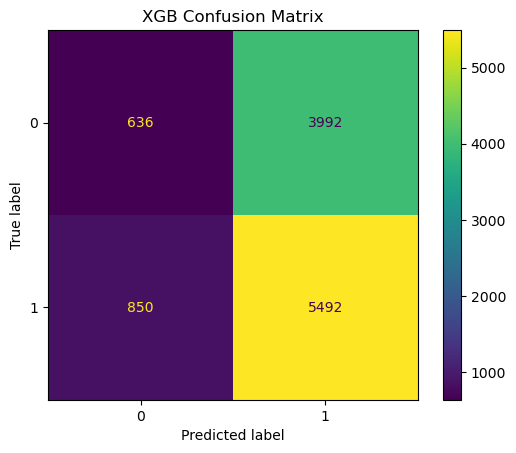

In [18]:

xgb_report = None
try:
    # Build train pairs with features: user features + item features + simple co-stats
    # Encode categoricals
    u_feat = users[['user_id','region','preferred_language','age_group','content_filter_level']].copy()
    for col in ['region','preferred_language','age_group','content_filter_level']:
        u_feat[col] = LabelEncoder().fit_transform(u_feat[col])

    w_feat = worlds[['world_id','category','sub_category','maturity_rating','avg_session_minutes','rating','total_ratings','likes']].copy()
    for col in ['category','sub_category','maturity_rating']:
        w_feat[col] = LabelEncoder().fit_transform(w_feat[col])

    # Positive samples from train
    pos = train[['user_id','world_id','score']].copy()
    pos['label']=1

    # Negative samples: sample worlds user hasn't interacted
    rng = np.random.default_rng(42)
    all_worlds = set(worlds['world_id'])
    user_pos = train.groupby('user_id')['world_id'].apply(set).to_dict()
    neg_rows = []
    for u, items in user_pos.items():
        neg_cands = list(all_worlds - items)
        for _ in range(min(5, len(items))):
            if not neg_cands: break
            w = rng.choice(neg_cands)
            neg_rows.append((u, w, 0.0, 0))
    neg = pd.DataFrame(neg_rows, columns=['user_id','world_id','score','label'])

    clf_df = pd.concat([pos[['user_id','world_id','label']], neg[['user_id','world_id','label']]], ignore_index=True)
    clf_df = clf_df.merge(u_feat, on='user_id', how='left').merge(w_feat, on='world_id', how='left')

    # Train/val split
    X = clf_df.drop(columns=['label','user_id','world_id'])
    y = clf_df['label']
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dval = xgb.DMatrix(X_val, label=y_val)
    params = {'objective': 'binary:logistic', 'eval_metric': 'auc', 'max_depth': 6, 'eta': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}
    bst = xgb.train(params, dtrain, num_boost_round=200, evals=[(dtrain,'train'), (dval,'valid')], verbose_eval=50)

    # Eval
    y_proba = bst.predict(dval)
    y_pred = (y_proba>=0.5).astype(int)
    auc = roc_auc_score(y_val, y_proba)
    acc = accuracy_score(y_val, y_pred)
    print(f"AUC={auc:.4f}, ACC={acc:.4f}")
    print(classification_report(y_val, y_pred))

    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(); plt.title("XGB Confusion Matrix"); plt.show()

    xgb_report = {'auc': float(auc), 'acc': float(acc)}

except Exception as e:
    print("XGBoost not available ->", e)


## 10) Tổng hợp kết quả & So sánh

,model,precision@10,recall@10,ndcg@10
1,SVD,0.004796,0.029770,0.014180
3,NCF,0.003976,0.024664,0.013363
5,VAE,0.003874,0.024014,0.012850
4,MLP,0.004243,0.025313,0.012766
0,ALS,0.004152,0.024331,0.012660
2,kNN,0.003894,0.023280,0.011960


<Figure size 640x480 with 0 Axes>

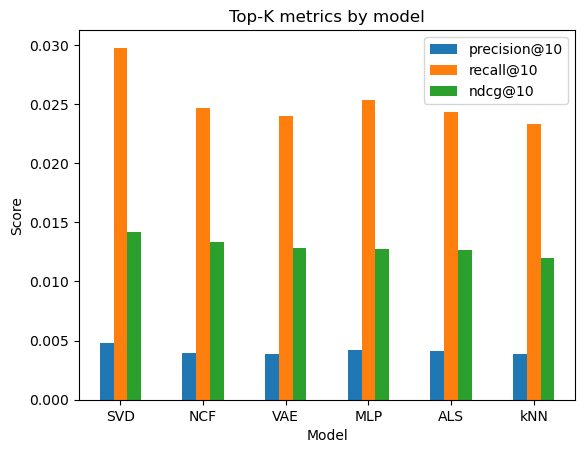

XGB: {'auc': 0.4973727781507379, 'acc': 0.5586144029170464}


In [43]:

results = []
def add_result(name, preds):
    if preds:
        p,r = precision_recall_at_k(preds, truth_by_user, 10)
        nd = ndcg_at_k(preds, truth_by_user, 10)
        results.append({'model': name, 'precision@10': p, 'recall@10': r, 'ndcg@10': nd})

add_result('ALS', als_preds)
add_result('SVD', svd_preds)
add_result('kNN', knn_preds)
add_result('NCF', ncf_preds)
add_result('MLP', mlp_preds)
add_result('VAE', vae_preds)

res_df = pd.DataFrame(results).sort_values('ndcg@10', ascending=False)
display(res_df)

# Plot bars
plt.figure()
res_df.set_index('model')[['precision@10','recall@10','ndcg@10']].plot(kind='bar')
plt.title("Top-K metrics by model")
plt.xlabel("Model"); plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

# Show XGB classification summary if available
if 'xgb_report' in globals() and xgb_report:
    print("XGB:", xgb_report)


## 11) Demo gợi ý cho 1 user

In [44]:

# Chọn ngẫu nhiên 1 user và in ra các gợi ý từ các model (nếu có)
uid = random.choice(sorted(filtered['u_idx'].unique().tolist()))
raw_user = u_enc.inverse_transform([uid])[0]
print("User:", raw_user)

def show_top(model_name, preds_dict, k=10):
    if preds_dict and uid in preds_dict:
        items = preds_dict[uid][:k]
        world_ids = i_enc.inverse_transform(items)
        print(f"{model_name} ->", list(world_ids))
    else:
        print(f"{model_name} -> N/A")

show_top("ALS", als_preds)
show_top("SVD", svd_preds)
show_top("kNN", knn_preds)
show_top("NCF", ncf_preds)
show_top("MLP", mlp_preds)
show_top("VAE", vae_preds)


User: U620142
ALS -> ['W1826176', 'W6438211', 'W2639776', 'W6129156', 'W4644029', 'W5389444', 'W8262421', 'W4619951', 'W4408419', 'W1920727']
SVD -> ['W3565618', 'W3629474', 'W9071034', 'W5702166', 'W5237380', 'W6467146', 'W5182213', 'W7812015', 'W4983136', 'W2178439']
kNN -> ['W5019935', 'W1554242', 'W8419801', 'W8570653', 'W9520621', 'W1428766', 'W4676992', 'W9812156', 'W3277912', 'W1998404']
NCF -> ['W2957655', 'W5041966', 'W1198994', 'W6768758', 'W6988263', 'W9520621', 'W6971158', 'W8479686', 'W8821189', 'W2516851']
MLP -> ['W5609574', 'W8486725', 'W2123422', 'W9125093', 'W7432313', 'W9313218', 'W3782022', 'W1216373', 'W8031845', 'W1918979']
VAE -> ['W5856164', 'W2187695', 'W6246087', 'W7774035', 'W5137110', 'W4713151', 'W5133856', 'W3569878', 'W4592931', 'W6092017']
